# 01 Setup

In [1]:
# !pip install medvqa -q

In [2]:
# # Install required libraries
# !pip install --upgrade pip
!pip install "wandb>=0.15"
!pip install datasets evaluate rouge_score transformers einops timm peft
# !pip install "accelerate>=0.26.0" 
# !pip install python-dotenv

In [3]:
!pip install "typing_extensions>=4.6.0" --upgrade --force-reinstall
!pip install --upgrade Pillow
!pip install ipywidgets

# import os
# os.kill(os.getpid(), 9)  # This restarts the runtime

  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
Using cached typing_extensions-4.16.0-py3-none-any.whl (45 kB)
  Attempting uninstall: typing_extensions
    Found existing installation: typing_extensions 4.16.0
    Uninstalling typing_extensions-4.16.0:
      Successfully uninstalled typing_extensions-4.16.0


# 02 Load Dataset, Model

In [4]:
import torch
import transformers.dynamic_module_utils
from transformers import AutoModelForCausalLM, AutoProcessor
from peft import get_peft_model, LoraConfig, TaskType

# 1. Bypass transformers checking for flash_attn (allows running without flash_attn)
def custom_check_imports(filename):
    imports = transformers.dynamic_module_utils.get_imports(filename)
    missing_packages = []
    for imp in imports:
        if imp == "flash_attn":
            continue  # Ignore flash_attn
        try:
            import importlib
            importlib.import_module(imp)
        except ImportError:
            missing_packages.append(imp)

    if len(missing_packages) > 0:
        raise ImportError(
            f"This modeling file requires the following packages that were not found in your environment: {', '.join(missing_packages)}. "
            f"Run `pip install {' '.join(missing_packages)}`"
        )
    return transformers.dynamic_module_utils.get_relative_imports(filename)

transformers.dynamic_module_utils.check_imports = custom_check_imports

# 2. Load Model & Processor
MODEL_ID = "microsoft/Florence-2-base-ft"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

print("Loading Florence-2 model...")
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, trust_remote_code=True)

print("Loading Florence-2 processor...")
processor = AutoProcessor.from_pretrained(MODEL_ID, trust_remote_code=True)

# 3. Apply LoRA adaptation for r=16
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "lm_head", "fc2"],
    task_type=TaskType.CAUSAL_LM,
    lora_dropout=0.05478,
    bias="none",
    inference_mode=False,
)

model = get_peft_model(model, lora_config)
model = model.to(device)
model.print_trainable_parameters()
print("Model and processor successfully initialized!")


Using device: cuda
Loading Florence-2 model...


/home/aidslab/Desktop/ImageCLEFmed-MEDVQA-GI-2025-Task1-Baseline_1/.venv/lib/python3.12/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Loading Florence-2 processor...
trainable params: 3,859,856 || all params: 235,273,872 || trainable%: 1.6405799620622556
Model and processor successfully initialized!


/home/aidslab/Desktop/ImageCLEFmed-MEDVQA-GI-2025-Task1-Baseline_1/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:789: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


In [5]:
# Import necessary modules
import transformers.dynamic_module_utils

# Bypass transformers checking for flash_attn
orig_check_imports = transformers.dynamic_module_utils.check_imports

def custom_check_imports(filename):
    imports = transformers.dynamic_module_utils.get_imports(filename)
    missing_packages = []
    for imp in imports:
        if imp == "flash_attn":
            continue  # Ignore flash_attn
        try:
            import importlib
            importlib.import_module(imp)
        except ImportError:
            missing_packages.append(imp)

    if len(missing_packages) > 0:
        raise ImportError(
            f"This modeling file requires the following packages that were not found in your environment: {', '.join(missing_packages)}. "
            f"Run `pip install {' '.join(missing_packages)}`"
        )
    return transformers.dynamic_module_utils.get_relative_imports(filename)

transformers.dynamic_module_utils.check_imports = custom_check_imports


# total_params = sum(p.numel() for p in model.parameters())
# print(f'total parameters: {total_params}')

# # Freeze vision tower
# for param in model.vision_tower.parameters():
#     param.requires_grad = False
# trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# print(f'trainable parameters: {trainable_params} {trainable_params/total_params:.2f}')

In [6]:
# Load dataset
from datasets import load_dataset

DATASET_COVERAGE = 1
SEED = 7
TEST_SIZE = 0.1

ds = load_dataset("SimulaMet-HOST/Kvasir-VQA")['raw']

if DATASET_COVERAGE < 1:
    dataset = ds.train_test_split(test_size=DATASET_COVERAGE, seed=SEED, shuffle=True)
    dataset = dataset['test'].train_test_split(test_size=TEST_SIZE, seed=SEED)
    train_dataset, val_dataset = dataset['train'], dataset['test']
else:
    dataset = ds.train_test_split(test_size=TEST_SIZE, seed=SEED)
    train_dataset, val_dataset = dataset['train'], dataset['test']

train_dataset.shape, val_dataset.shape, train_dataset.shape[0] + val_dataset.shape[0], ds.shape


Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/30 [00:00<?, ?it/s]

((52964, 5), (5885, 5), 58849, (58849, 5))

In [7]:
def collate_fn(batch):
    questions = [f"{x['question']}" for x in batch]
    images = [x["image"].convert("RGB") if x["image"].mode != "RGB" else x["image"] for x in batch]
    answers = [x["answer"] for x in batch]

    inputs = processor(text=questions, images=images, return_tensors="pt", padding=True)
    labels = processor.tokenizer(answers, return_tensors="pt", padding=True).input_ids
    labels[labels == processor.tokenizer.pad_token_id] = -100
    inputs["labels"] = labels
    return inputs

# 03 Error Metrics

In [8]:
# (optional) if you want to evaluate with NLP or other metrics
import evaluate
import numpy as np

bleu, meteor, rouge = map(evaluate.load, ["bleu", "meteor", "rouge"])

# def compute_metrics(eval_pred):
#     preds, labels = eval_pred
#     preds = processor.tokenizer.batch_decode(np.argmax(preds[0], axis=-1), skip_special_tokens=True)
#     labels = processor.tokenizer.batch_decode(np.where(labels != -100, labels, processor.tokenizer.pad_token_id), skip_special_tokens=True)
#     preds, labels = [p.strip() for p in preds], [l.strip() for l in labels]

#     return {
#         # "bleu": bleu.compute(predictions=preds, references=[[l] for l in labels])["bleu"],
#         # "meteor": meteor.compute(predictions=preds, references=labels)["meteor"],
#         "rougeL": rouge.compute(predictions=preds, references=labels)["rougeL"],
#     }

[nltk_data] Downloading package wordnet to /home/aidslab/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/aidslab/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/aidslab/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [9]:
# import wandb
# wandb.login()

In [10]:
import math
from transformers import TrainingArguments, Trainer

# ==== Hyperparameters ====
MODEL_NAME = 'florence2'
TRAIN_DATASET_SIZE = len(train_dataset)

PER_DEVICE_TRAIN_BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 16
PER_DEVICE_EVAL_BATCH_SIZE = 4
EVAL_ACCUMULATION_STEPS = 1
BASE_LEARNING_RATE = 9.6e-5
WEIGHT_DECAY = 0.07

NUM_EPOCHS = 5
LOGGING_STEPS = 10

# ==== Derived Values ====
effective_batch_size = PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
scaled_learning_rate = BASE_LEARNING_RATE * math.sqrt((effective_batch_size / 20))
steps_per_epoch = math.ceil(TRAIN_DATASET_SIZE / effective_batch_size)
max_steps = steps_per_epoch * NUM_EPOCHS

run_name = f"{MODEL_NAME}_{effective_batch_size}_r16"

# ==== Training Arguments ====
training_args = TrainingArguments(
    push_to_hub=False,
    # hub_strategy="every_save",
    # hub_model_id=f"gauravparajuli/{run_name}",
    output_dir=run_name,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=PER_DEVICE_EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    eval_accumulation_steps=EVAL_ACCUMULATION_STEPS,
    max_steps=max_steps,
    learning_rate=BASE_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    logging_steps=LOGGING_STEPS,
    save_strategy="steps",
    save_steps=steps_per_epoch,        # once per epoch
    evaluation_strategy="steps",       # compatible with transformers < 4.41.0
    eval_steps=steps_per_epoch,        # once per epoch
    report_to="wandb",
    save_total_limit=3,
    remove_unused_columns=False,
    fp16=True,
    load_best_model_at_end=True,
    greater_is_better=True
)

print(f'num epochs: {NUM_EPOCHS}')
print('base learning rate: ', BASE_LEARNING_RATE)
print(run_name)


num epochs: 5
base learning rate:  9.6e-05
florence2_64_r16


/home/aidslab/Desktop/ImageCLEFmed-MEDVQA-GI-2025-Task1-Baseline_1/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:789: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


In [11]:
import wandb
import shutil
from transformers import EarlyStoppingCallback

wandb.init(
    project="ImageClef2025VQA",
    name=run_name,  # same run_name you're using above
    config={
        "batch_size": PER_DEVICE_TRAIN_BATCH_SIZE,
        "grad_acc_steps": GRADIENT_ACCUMULATION_STEPS,
        "effective_batch_size": effective_batch_size,
        "base_learning_rate": BASE_LEARNING_RATE,
        "num_epochs": NUM_EPOCHS,
    }
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=collate_fn,
    # compute_metrics=compute_metrics,
    # callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

# trainer = Trainer(
#     model=model,
#     args=training_args,
#     train_dataset=train_dataset,
#     eval_dataset=val_dataset,
#     data_collator=collate_fn,
#     compute_metrics=compute_metrics # if you want to evaluate with NLP or other metrics (optional)
# )

trainer.train()
wandb.finish()
shutil.rmtree(training_args.output_dir)

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.


/home/aidslab/Desktop/ImageCLEFmed-MEDVQA-GI-2025-Task1-Baseline_1/.venv/lib/python3.12/site-packages/accelerate/accelerator.py:479: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)
max_steps is given, it will override any value given in num_train_epochs


  0%|          | 0/4140 [00:00<?, ?it/s]

{'loss': 2.5094, 'grad_norm': 3.607193946838379, 'learning_rate': 9.576811594202899e-05, 'epoch': 0.01}
{'loss': 1.9228, 'grad_norm': 3.9394595623016357, 'learning_rate': 9.553623188405798e-05, 'epoch': 0.02}
{'loss': 1.3875, 'grad_norm': 3.062770128250122, 'learning_rate': 9.530434782608695e-05, 'epoch': 0.04}
{'loss': 1.105, 'grad_norm': 3.0983123779296875, 'learning_rate': 9.507246376811594e-05, 'epoch': 0.05}
{'loss': 0.8323, 'grad_norm': 3.266860008239746, 'learning_rate': 9.484057971014493e-05, 'epoch': 0.06}
{'loss': 0.6358, 'grad_norm': 2.8995985984802246, 'learning_rate': 9.460869565217393e-05, 'epoch': 0.07}
{'loss': 0.5153, 'grad_norm': 2.71427321434021, 'learning_rate': 9.43768115942029e-05, 'epoch': 0.08}
{'loss': 0.4241, 'grad_norm': 4.382436275482178, 'learning_rate': 9.414492753623189e-05, 'epoch': 0.1}
{'loss': 0.4423, 'grad_norm': 3.6904265880584717, 'learning_rate': 9.391304347826087e-05, 'epoch': 0.11}
{'loss': 0.4255, 'grad_norm': 2.6581873893737793, 'learning_rate

  0%|          | 0/1472 [00:00<?, ?it/s]

...

{'loss': 0.0924, 'grad_norm': 1.1928226947784424, 'learning_rate': 1.9014492753623188e-05, 'epoch': 4.01}
{'loss': 0.079, 'grad_norm': 1.223781943321228, 'learning_rate': 1.8782608695652175e-05, 'epoch': 4.02}
{'loss': 0.091, 'grad_norm': 1.0370007753372192, 'learning_rate': 1.855072463768116e-05, 'epoch': 4.04}
{'loss': 0.0894, 'grad_norm': 1.5743921995162964, 'learning_rate': 1.8318840579710143e-05, 'epoch': 4.05}
{'loss': 0.0786, 'grad_norm': 1.1976466178894043, 'learning_rate': 1.808695652173913e-05, 'epoch': 4.06}
{'loss': 0.0846, 'grad_norm': 0.8962109088897705, 'learning_rate': 1.7855072463768114e-05, 'epoch': 4.07}
{'loss': 0.091, 'grad_norm': 1.2657554149627686, 'learning_rate': 1.76231884057971e-05, 'epoch': 4.08}
{'loss': 0.0795, 'grad_norm': 0.8824402093887329, 'learning_rate': 1.739130434782609e-05, 'epoch': 4.1}
{'loss': 0.0814, 'grad_norm': 1.3596551418304443, 'learning_rate': 1.7159420289855073e-05, 'epoch': 4.11}
{'loss': 0.0821, 'grad_norm': 1.6882494688034058, 'learn

  0%|          | 0/1472 [00:00<?, ?it/s]

/home/aidslab/Desktop/ImageCLEFmed-MEDVQA-GI-2025-Task1-Baseline_1/.venv/lib/python3.12/site-packages/peft/utils/save_and_load.py:139: UserWarning: Setting `save_embedding_layers` to `True` as embedding layers found in `target_modules`.
  warnings.warn("Setting `save_embedding_layers` to `True` as embedding layers found in `target_modules`.")
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


{'eval_loss': 0.08026666194200516, 'eval_runtime': 337.2743, 'eval_samples_per_second': 17.449, 'eval_steps_per_second': 4.364, 'epoch': 5.0}
{'train_runtime': 32366.765, 'train_samples_per_second': 8.186, 'train_steps_per_second': 0.128, 'train_loss': 0.13057157637704397, 'epoch': 5.0}


eval/loss,█▄▃▁▁
eval/runtime,▁█▅█▄
eval/samples_per_second,█▁▄▁▅
eval/steps_per_second,█▁▄▁▄
train/epoch,▁▁▁▂▂▂▂▂▂▂▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇██
train/global_step,▁▁▁▁▁▂▂▂▂▂▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇█████
train/grad_norm,██▆▄▄▃▃▃▂▃▃▃▅▂▄▃▃▂▃▄▂▂▂▂▂▂▂▂▂▂▂▁▁▁▃▂▃▂▁▁
train/learning_rate,█▇▇▇▇▆▆▆▆▆▆▆▅▅▅▅▅▅▅▄▄▄▄▄▄▃▃▃▃▃▃▃▃▂▂▂▂▂▁▁
train/loss,█▅▂▂▂▂▁▂▁▂▁▁▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/loss,0.08027
eval/runtime,337.2743


# Inference

Q: Is there a green/black box artefact?
Model: yes
GT: yes


/home/aidslab/Desktop/ImageCLEFmed-MEDVQA-GI-2025-Task1-Baseline_1/.venv/lib/python3.12/site-packages/transformers/generation/utils.py:1141: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


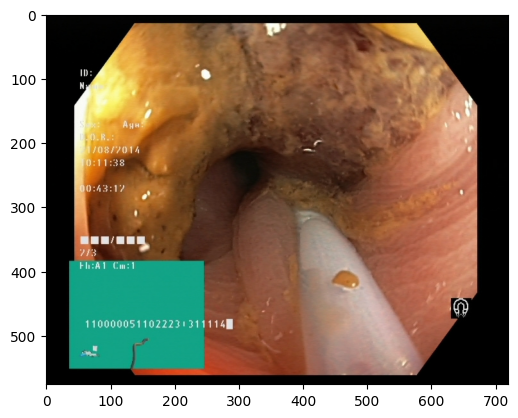

In [12]:
# ReRun this block to generate for new ramdom sample
import random
sample = [val_dataset[random.randint(0, len(val_dataset)-1)]] # rerun this block to generate new sample
import matplotlib.pyplot as plt; plt.imshow(sample[0]['image'])
inputs = collate_fn(sample)
inputs = {k: v.to(device) for k, v in inputs.items() if k not in ['labels', 'attention_mask']}

with torch.no_grad():
    output = model.generate(**inputs)

print(f"Q: {sample[0]['question']}\nModel: {processor.tokenizer.decode(output[0], skip_special_tokens=True)}\nGT: {sample[0]['answer']}")